In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
import mahotas
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C3"
DTYPE="HRLK"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C3_10,27,"[DATA/TRAINING/C3/C3_10/IMG_6627.HEIC, DATA/TR..."
1,C3_11,27,"[DATA/TRAINING/C3/C3_11/IMG_6732.HEIC, DATA/TR..."
2,C3_12,27,"[DATA/TRAINING/C3/C3_12/IMG_6854.HEIC, DATA/TR..."
3,C3_13,30,"[DATA/TRAINING/C3/C3_13/IMG_7002.HEIC, DATA/TR..."
4,C3_14,27,"[DATA/TRAINING/C3/C3_14/IMG_7249.HEIC, DATA/TR..."
5,C3_15,26,"[DATA/TRAINING/C3/C3_15/IMG_7385.HEIC, DATA/TR..."
6,C3_16,26,"[DATA/TRAINING/C3/C3_16/IMG_7516.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_6627.HEIC')

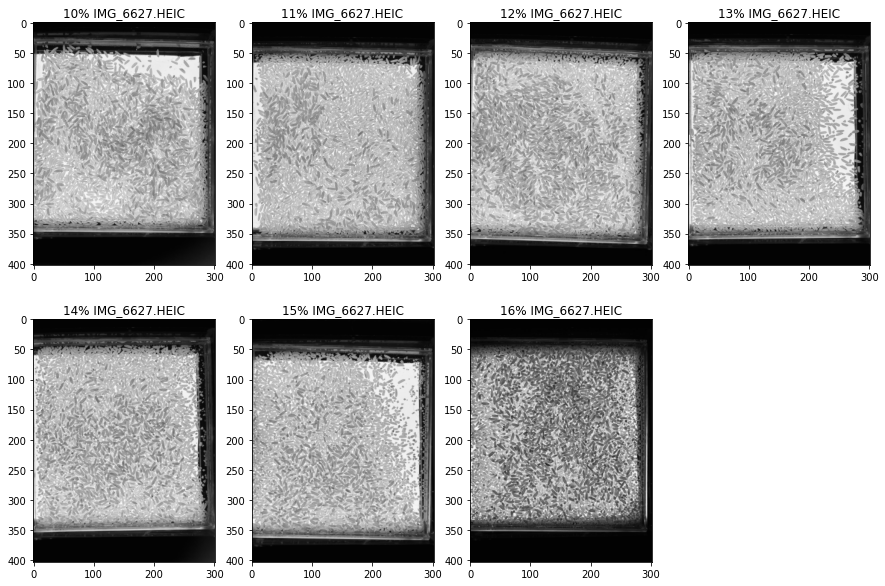

In [6]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][0].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[0][0].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[0][0].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[0][0].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[0][0].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[0][0].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[0][0].split("/")[4])

In [239]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=20
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [240]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.008363,224.494591,0.982142,6285.663191,0.370689,274.195713,24918.158175,8.175535,11.607723,0.000448,...,0.000313,4.629978,-0.328913,0.995744,20,806,604,3,IMG_6627.HEIC,10
1,0.009391,233.030429,0.981822,6409.570266,0.359335,267.938284,25405.250636,8.114674,11.621005,0.000425,...,0.000285,4.702743,-0.313302,0.994505,20,806,604,3,IMG_6628.HEIC,10
2,0.009343,219.583328,0.982321,6210.253464,0.354413,271.384994,24621.430528,8.172872,11.730329,0.000415,...,0.000286,4.685715,-0.316808,0.995020,20,806,604,3,IMG_6629.HEIC,10
3,0.008958,216.698429,0.982722,6270.840977,0.356513,268.881134,24866.665477,8.230632,11.774018,0.000419,...,0.000288,4.680179,-0.321444,0.995500,20,806,604,3,IMG_6630.HEIC,10
4,0.008883,208.777628,0.982915,6109.795156,0.345267,270.960292,24230.402995,8.179461,11.743725,0.000405,...,0.000282,4.668761,-0.316652,0.994996,20,806,604,3,IMG_6631.HEIC,10
5,0.008973,208.747431,0.982496,5962.843508,0.347918,270.303818,23642.626600,8.196459,11.769211,0.000411,...,0.000281,4.679826,-0.315260,0.994960,20,806,604,3,IMG_6632.HEIC,10
6,0.008714,228.814676,0.981690,6248.419003,0.358882,267.470079,24764.861337,8.198645,11.734921,0.000428,...,0.000299,4.649432,-0.322351,0.995452,20,806,604,3,IMG_6633.HEIC,10
7,0.008654,231.607428,0.979936,5771.618500,0.333995,266.905738,22854.866570,8.205084,11.866549,0.000384,...,0.000264,4.756878,-0.305816,0.994228,20,806,604,3,IMG_6634.HEIC,10
8,0.009030,218.677461,0.981730,5984.497685,0.345173,263.943323,23719.313278,8.216242,11.814735,0.000402,...,0.000270,4.722747,-0.311727,0.994768,20,806,604,3,IMG_6635.HEIC,10
9,0.008619,223.252013,0.981507,6036.224958,0.343561,269.168506,23921.647817,8.227603,11.846042,0.000399,...,0.000274,4.720440,-0.314044,0.994953,20,806,604,3,IMG_6636.HEIC,10


# Classification

In [241]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [242]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [243]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [244]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [245]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [246]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.578947,0.619048,0.547619,0.581147,HRLK,C3,RF_C,20,806,604,3
1,2,0.842105,0.869048,0.857143,0.863054,HRLK,C3,RF_C,20,806,604,3
2,3,0.947368,0.964286,0.952381,0.958296,HRLK,C3,RF_C,20,806,604,3
3,4,0.842105,0.892857,0.857143,0.874636,HRLK,C3,RF_C,20,806,604,3
4,5,0.894737,0.928571,0.880952,0.904135,HRLK,C3,RF_C,20,806,604,3
5,6,0.894737,0.916667,0.880952,0.898455,HRLK,C3,RF_C,20,806,604,3
6,7,0.789474,0.809524,0.809524,0.809524,HRLK,C3,RF_C,20,806,604,3
7,8,0.789474,0.823810,0.785714,0.804311,HRLK,C3,RF_C,20,806,604,3
8,9,0.894737,0.904762,0.904762,0.904762,HRLK,C3,RF_C,20,806,604,3
9,10,0.736842,0.823810,0.761905,0.791649,HRLK,C3,RF_C,20,806,604,3


In [247]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C3,RF_C,0.821053,0.82381,0.838997,0.855238


### MLP Classifier

In [248]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [249]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [250]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.842105,0.880952,0.857143,0.868885,HRLK,C3,MLP_C,20,806,604,3
1,2,0.842105,0.907143,0.833333,0.868673,HRLK,C3,MLP_C,20,806,604,3
2,3,0.894737,0.916667,0.904762,0.910675,HRLK,C3,MLP_C,20,806,604,3
3,4,0.578947,0.750000,0.571429,0.648649,HRLK,C3,MLP_C,20,806,604,3
4,5,0.842105,0.895238,0.833333,0.863177,HRLK,C3,MLP_C,20,806,604,3
5,6,0.789474,0.845238,0.761905,0.801411,HRLK,C3,MLP_C,20,806,604,3
6,7,0.842105,0.892857,0.857143,0.874636,HRLK,C3,MLP_C,20,806,604,3
7,8,0.894737,0.928571,0.880952,0.904135,HRLK,C3,MLP_C,20,806,604,3
8,9,0.842105,0.892857,0.857143,0.874636,HRLK,C3,MLP_C,20,806,604,3
9,10,0.736842,0.809524,0.738095,0.772161,HRLK,C3,MLP_C,20,806,604,3


In [251]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C3,MLP_C,0.810526,0.809524,0.838704,0.871905


### XGBoost Classifier

In [252]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [253]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.842105,0.880952,0.857143,0.868885,HRLK,C3,XGB_C,20,806,604,3
1,2,0.684211,0.654762,0.690476,0.672145,HRLK,C3,XGB_C,20,806,604,3
2,3,0.842105,0.928571,0.833333,0.878378,HRLK,C3,XGB_C,20,806,604,3
3,4,0.578947,0.523810,0.619048,0.567460,HRLK,C3,XGB_C,20,806,604,3
4,5,0.842105,0.869048,0.857143,0.863054,HRLK,C3,XGB_C,20,806,604,3
5,6,0.789474,0.871429,0.738095,0.799239,HRLK,C3,XGB_C,20,806,604,3
6,7,0.631579,0.747619,0.666667,0.704826,HRLK,C3,XGB_C,20,806,604,3
7,8,0.684211,0.702381,0.666667,0.684058,HRLK,C3,XGB_C,20,806,604,3
8,9,0.736842,0.842857,0.738095,0.787005,HRLK,C3,XGB_C,20,806,604,3
9,10,0.789474,0.892857,0.785714,0.835866,HRLK,C3,XGB_C,20,806,604,3


In [254]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C3,XGB_C,0.742105,0.745238,0.766092,0.791429


# External validation

In [255]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C3_10,5,"[DATA/TEST/C3/C3_10/IMG_6622.HEIC, DATA/TEST/C..."
1,C3_11,5,"[DATA/TEST/C3/C3_11/IMG_6717.HEIC, DATA/TEST/C..."
2,C3_12,5,"[DATA/TEST/C3/C3_12/IMG_6845.HEIC, DATA/TEST/C..."
3,C3_13,5,"[DATA/TEST/C3/C3_13/IMG_6987.HEIC, DATA/TEST/C..."
4,C3_14,5,"[DATA/TEST/C3/C3_14/IMG_7239.HEIC, DATA/TEST/C..."
5,C3_15,5,"[DATA/TEST/C3/C3_15/IMG_7376.HEIC, DATA/TEST/C..."
6,C3_16,5,"[DATA/TEST/C3/C3_16/IMG_7506.HEIC, DATA/TEST/C..."


In [256]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [257]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [258]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.009274,232.527392,0.982648,6700.212592,0.378777,270.577534,26568.322977,8.090610,11.493920,0.000464,...,0.000315,4.627008,-0.323632,0.995186,20,806,604,3,IMG_6622.HEIC,10
1,0.009968,234.781197,0.982171,6584.407301,0.375852,264.975816,26102.848005,8.045648,11.459829,0.000461,...,0.000308,4.652578,-0.317456,0.994597,20,806,604,3,IMG_6623.HEIC,10
2,0.009393,227.053640,0.982996,6676.496933,0.391432,271.905732,26478.934091,8.143421,11.502607,0.000489,...,0.000327,4.600199,-0.332823,0.995952,20,806,604,3,IMG_6624.HEIC,10
3,0.009642,230.558671,0.982261,6498.684390,0.376736,271.014181,25764.178891,8.120346,11.541568,0.000461,...,0.000310,4.637363,-0.322609,0.995210,20,806,604,3,IMG_6625.HEIC,10
4,0.008972,230.025970,0.981517,6222.494720,0.345484,271.999601,24659.952911,8.071891,11.616396,0.000402,...,0.000283,4.697691,-0.309378,0.993995,20,806,604,3,IMG_6626.HEIC,10
0,0.017185,231.649581,0.981312,6197.685869,0.348959,261.714208,24559.093897,7.936720,11.507122,0.000402,...,0.000276,4.757460,-0.299747,0.992756,20,806,604,3,IMG_6717.HEIC,11
1,0.017058,225.109934,0.982329,6369.445906,0.355474,260.785160,25252.673690,7.989603,11.535769,0.000414,...,0.000282,4.733541,-0.307048,0.993683,20,806,604,3,IMG_6721.HEIC,11
2,0.016108,236.070880,0.981298,6311.337501,0.353799,266.775702,25009.279125,7.918183,11.450012,0.000411,...,0.000289,4.691610,-0.306279,0.993266,20,806,604,3,IMG_6724.HEIC,11
3,0.016998,200.626983,0.984818,6607.266589,0.383191,266.093604,26228.439372,7.951222,11.323714,0.000469,...,0.000311,4.646118,-0.320345,0.994642,20,806,604,3,IMG_6728.HEIC,11
4,0.016311,225.941220,0.982419,6425.785656,0.370701,269.573279,25477.201405,7.979519,11.459583,0.000443,...,0.000307,4.661410,-0.317007,0.994471,20,806,604,3,IMG_6731.HEIC,11


In [259]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [260]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [261]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [262]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [263]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.62      1.00      0.77         5
     Class 1       1.00      0.60      0.75         5
     Class 2       0.83      1.00      0.91         5
     Class 3       0.00      0.00      0.00         5
     Class 4       0.40      0.40      0.40         5
     Class 5       1.00      0.80      0.89         5
     Class 6       0.71      1.00      0.83         5

    accuracy                           0.69        35
   macro avg       0.65      0.69      0.65        35
weighted avg       0.65      0.69      0.65        35



## MLP

In [264]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [265]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.50      0.20      0.29         5
     Class 1       0.60      0.60      0.60         5
     Class 2       0.56      1.00      0.71         5
     Class 3       0.00      0.00      0.00         5
     Class 4       0.50      0.40      0.44         5
     Class 5       0.60      0.60      0.60         5
     Class 6       0.62      1.00      0.77         5

    accuracy                           0.54        35
   macro avg       0.48      0.54      0.49        35
weighted avg       0.48      0.54      0.49        35



## XGBC

In [266]:
y_pred = modelXGBC.predict(X_test_scale) 

In [267]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.71      1.00      0.83         5
     Class 1       1.00      0.60      0.75         5
     Class 2       0.62      1.00      0.77         5
     Class 3       0.00      0.00      0.00         5
     Class 4       0.67      0.40      0.50         5
     Class 5       0.80      0.80      0.80         5
     Class 6       0.71      1.00      0.83         5

    accuracy                           0.69        35
   macro avg       0.65      0.69      0.64        35
weighted avg       0.65      0.69      0.64        35

